# Assignment 6 - Matplotlib and Seaborn
**Jasroop Singh Sachdeva**
Roll Number: 1024170090

Note: `company_sales_data.csv` (used in Q.4) is included in the repository.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
## Q.1 Plot y = M·x² and y = M·sin(x)

Enter the value of M: 3


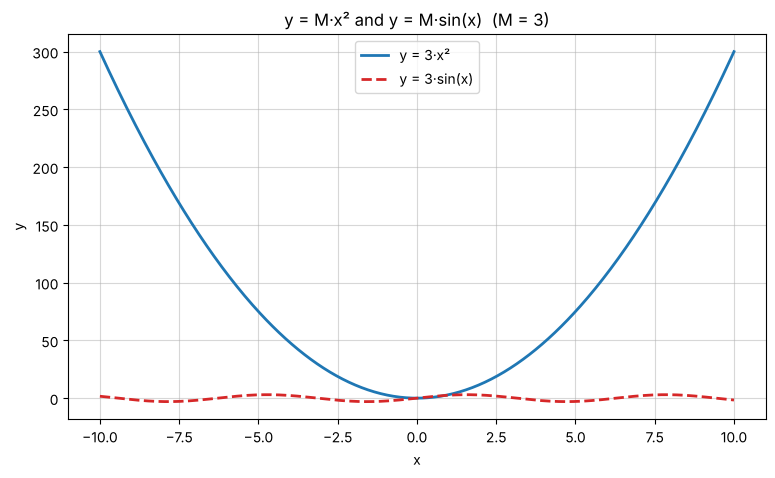

In [2]:
M = float(input("Enter the value of M: "))

x = np.linspace(-10, 10, 500)
y1 = M * x**2
y2 = M * np.sin(x)

plt.figure(figsize=(9, 5))
plt.plot(x, y1, color="tab:blue", linestyle="-", linewidth=2, label=f"y = {M:g}·x²")
plt.plot(x, y2, color="tab:red", linestyle="--", linewidth=2, label=f"y = {M:g}·sin(x)")
plt.title(f"y = M·x² and y = M·sin(x)  (M = {M:g})")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

---
## Q.2 Subject scores - Seaborn bar plot

In [3]:
data = {
    "Subject": ["Maths", "Physics", "Chemistry", "English", "Computer Science"],
    "Score": [88, 76, 69, 82, 94]
}
df = pd.DataFrame(data)
print(df)

            Subject  Score
0             Maths     88
1           Physics     76
2         Chemistry     69
3           English     82
4  Computer Science     94


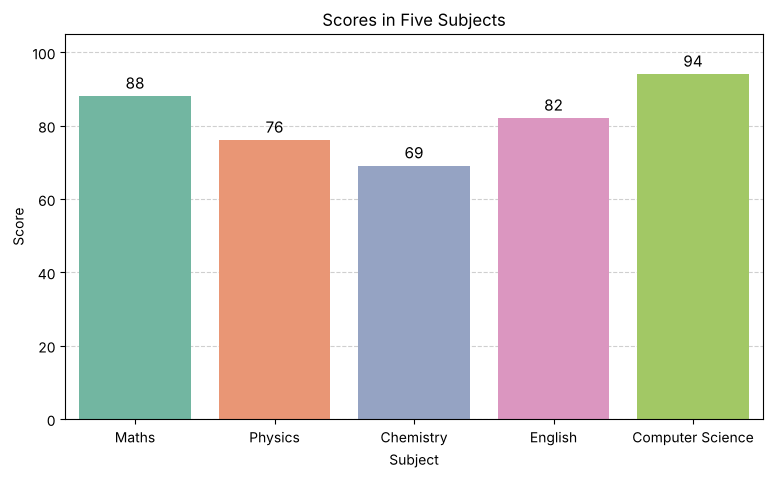

In [4]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=df, x="Subject", y="Score", hue="Subject", palette="Set2", legend=False)

# write the score on top of each bar
for bar in ax.patches:
    ax.annotate(f"{bar.get_height():.0f}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=11, xytext=(0, 3), textcoords="offset points")

plt.title("Scores in Five Subjects")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.ylim(0, 105)
plt.grid(axis="y", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
plt.show()

---
## Q.3 Random data with roll number as seed - 2x2 subplots
Top row has the two plots asked in the question (cumulative sum and scatter with noise). I used the bottom two for a histogram and a box plot of the same data.

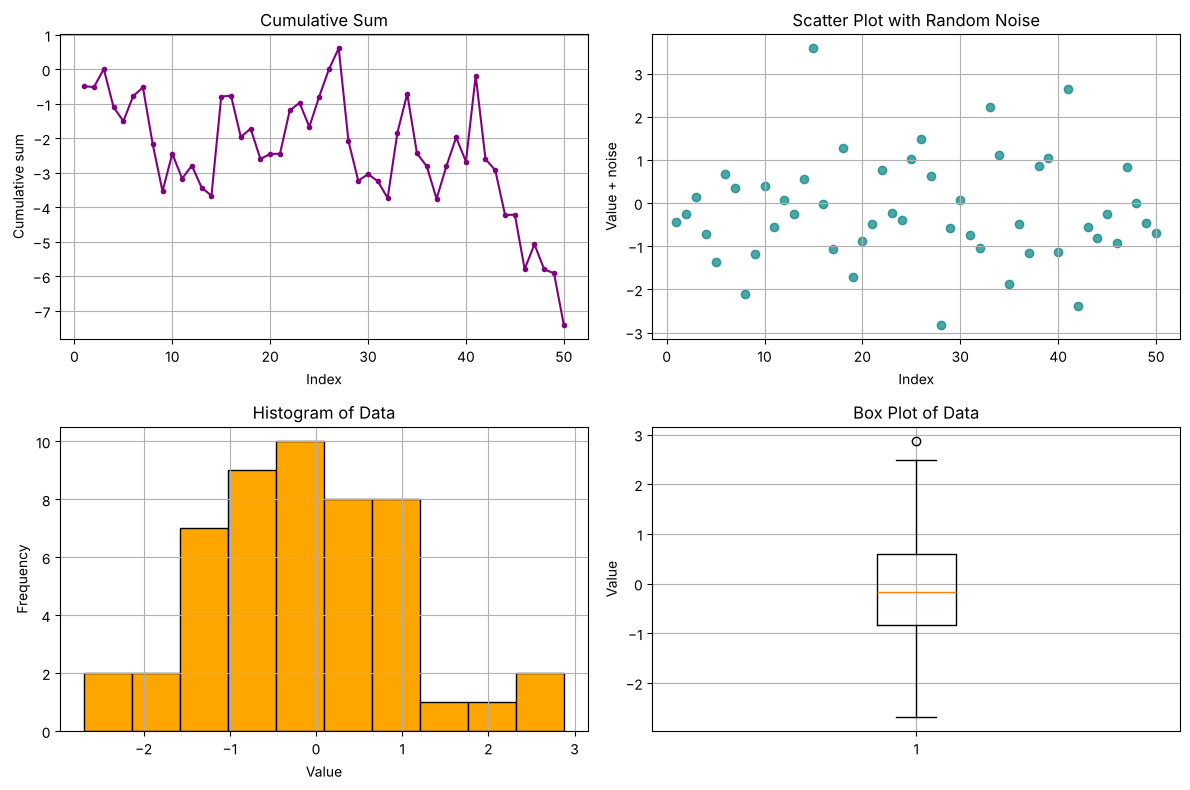

In [5]:
roll_no = 1024170090
np.random.seed(roll_no)

data = np.random.randn(50)
noise = np.random.randn(50) * 0.5
idx = np.arange(1, 51)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(idx, np.cumsum(data), color="purple", marker="o", markersize=3)
axes[0, 0].set_title("Cumulative Sum")
axes[0, 0].set_xlabel("Index")
axes[0, 0].set_ylabel("Cumulative sum")
axes[0, 0].grid(True)

axes[0, 1].scatter(idx, data + noise, color="teal", alpha=0.7)
axes[0, 1].set_title("Scatter Plot with Random Noise")
axes[0, 1].set_xlabel("Index")
axes[0, 1].set_ylabel("Value + noise")
axes[0, 1].grid(True)

axes[1, 0].hist(data, bins=10, color="orange", edgecolor="black")
axes[1, 0].set_title("Histogram of Data")
axes[1, 0].set_xlabel("Value")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].grid(True)

axes[1, 1].boxplot(data)
axes[1, 1].set_title("Box Plot of Data")
axes[1, 1].set_ylabel("Value")
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

---
## Q.4 Company sales data
Dataset: https://github.com/AnjulaMehto/MCA/blob/main/company_sales_data.csv

In [6]:
sales = pd.read_csv("company_sales_data.csv")
print(sales.head())

   month_number  facecream  facewash  toothpaste  bathingsoap  shampoo  \
0             1       2500      1500        5200         9200     1200   
1             2       2630      1200        5100         6100     2100   
2             3       2140      1340        4550         9550     3550   
3             4       3400      1130        5870         8870     1870   
4             5       3600      1740        4560         7760     1560   

   moisturizer  total_units  total_profit  
0         1500        21100        211000  
1         1200        18330        183300  
2         1340        22470        224700  
3         1130        22270        222700  
4         1740        20960        209600  


**1. Total profit of all months - line plot**

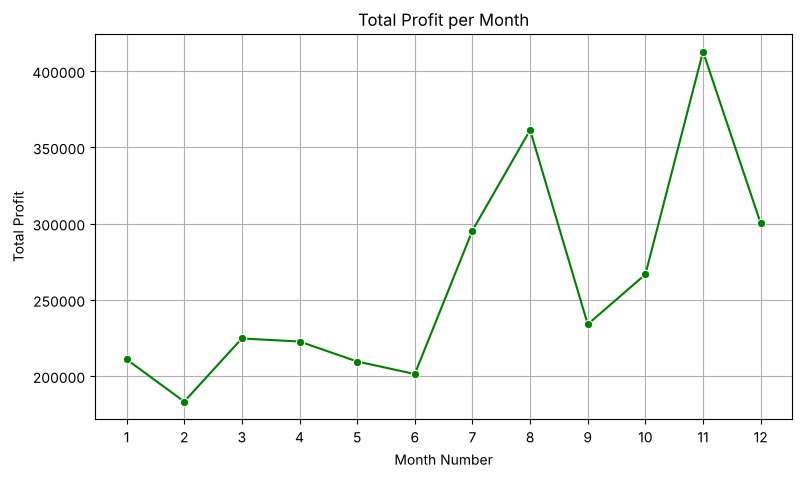

In [7]:
plt.figure(figsize=(9, 5))
sns.lineplot(data=sales, x="month_number", y="total_profit", marker="o", color="green")
plt.title("Total Profit per Month")
plt.xlabel("Month Number")
plt.ylabel("Total Profit")
plt.xticks(sales["month_number"])
plt.grid(True)
plt.show()

**2. Sales of all products - multiline plot**

Converted the product columns to long format with `melt` so seaborn can draw one line per product using `hue`.

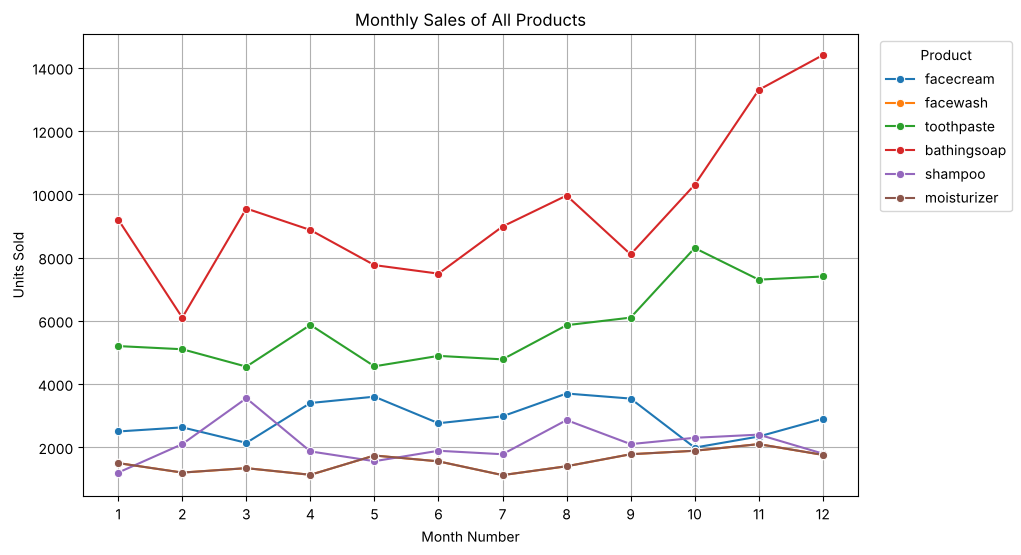

In [8]:
products = ["facecream", "facewash", "toothpaste", "bathingsoap", "shampoo", "moisturizer"]
product_sales = sales.melt(id_vars="month_number", value_vars=products,
                           var_name="Product", value_name="Units Sold")

plt.figure(figsize=(10, 6))
sns.lineplot(data=product_sales, x="month_number", y="Units Sold", hue="Product", marker="o")
plt.title("Monthly Sales of All Products")
plt.xlabel("Month Number")
plt.ylabel("Units Sold")
plt.xticks(sales["month_number"])
plt.grid(True)
plt.legend(title="Product", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**3. Bar chart for all the features**

One bar chart per column (month on x-axis).

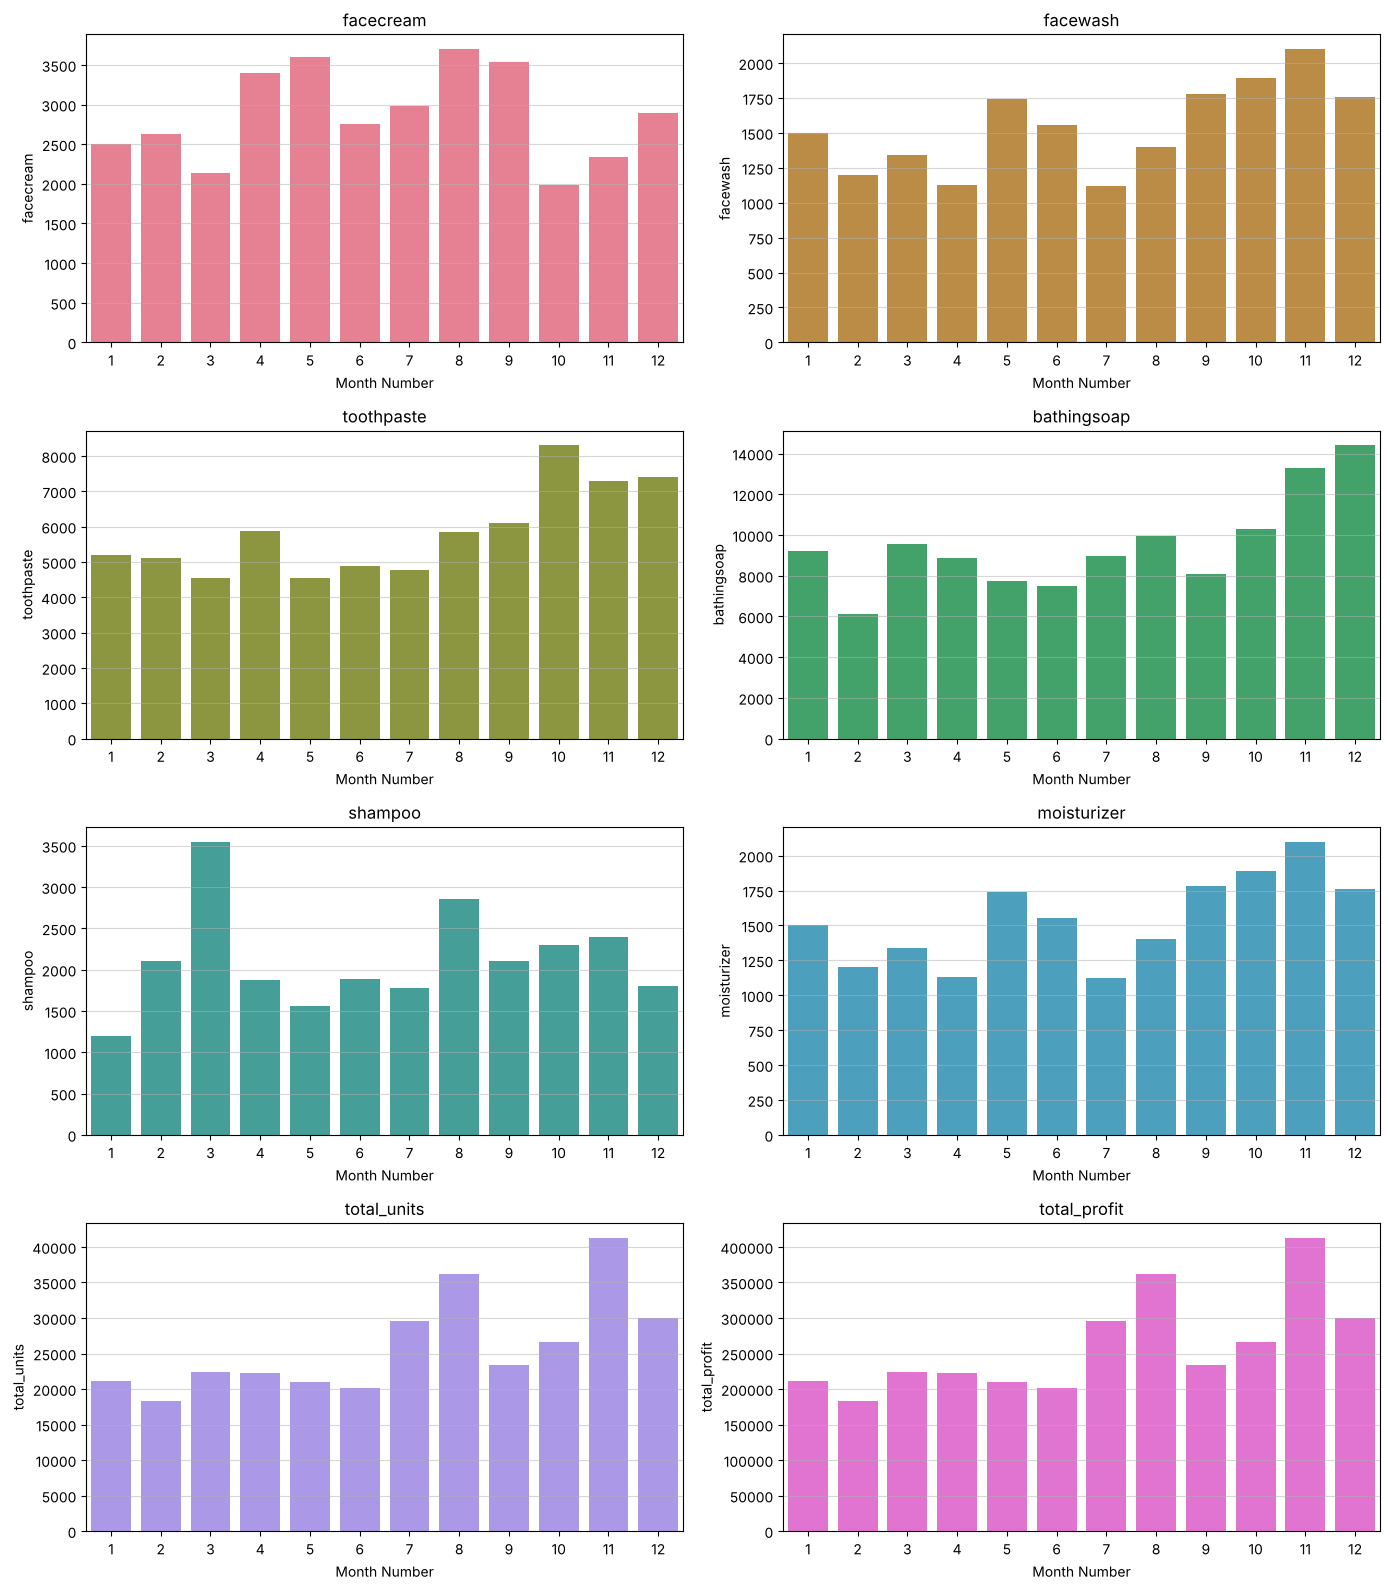

In [9]:
features = sales.columns.drop("month_number")

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.barplot(data=sales, x="month_number", y=col, ax=axes[i], color=sns.color_palette("husl", 8)[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("Month Number")
    axes[i].set_ylabel(col)
    axes[i].grid(axis="y", alpha=0.5)

plt.tight_layout()
plt.show()